# Dönüşüm arttı. Yeni akışı yaygınlaştıralım mı?

Sipariş ekranı sadeleşiyor. Ekip dönüşümü artırmak istiyor, destek ekibi ise şikayet yükünün büyümemesini istiyor. Sonucu görmeden iki koşul belirleniyor. Dönüşüm farkının alt ucu +2 yüzde puanı aşmalı veya eşit olmalı; şikayet farkının üst ucu +1,5 yüzde puanı aşmamalı.

Karar: Sabit deney sonunda iki koşul birlikte sağlanıyor mu?

Veriler sentetiktir. Her senaryo sabit tohumla aynı veriyi yeniden oluşturur. CSV dosyaları örnek çıktıdır. Bir CSV’yi değiştirmen bu defterin verisini otomatik değiştirmez.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = '#2457ad', '#ac452c', '#197254', '#64748b'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .19})

def table(frame, title):
    return dict(title=title, columns=frame.columns.tolist(),
                rows=frame.astype(object).where(frame.notna(), None).values.tolist())

def experiment(scenario='default'):
    rng = np.random.default_rng(72102)
    n = 4000
    z = stats.norm.ppf(.975)
    p0, p1 = .10,.13
    pbar = (p0+p1)/2
    planned = int(np.ceil((z*np.sqrt(2*pbar*(1-pbar)) + stats.norm.ppf(.8)*np.sqrt(p0*(1-p0)+p1*(1-p1)))**2/(p1-p0)**2))
    assignment = np.repeat(['A','B'],n)
    rng.shuffle(assignment)
    is_b = assignment=='B'
    conversion = (rng.random(2*n) < np.where(is_b,.146,.10)).astype(int)
    complaint = (rng.random(2*n) < np.where(is_b,.045 if scenario=='complaints' else .020,.019)).astype(int)
    raw = pd.DataFrame({'Müşteri':np.arange(1,2*n+1),'Kol':assignment,'Dönüşüm':conversion,'Şikayet':complaint})
    def wilson(k,n):
        p = k/n
        denom=1+z*z/n
        mid=(p+z*z/(2*n))/denom
        radius=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denom
        return mid-radius,mid+radius
    rows=[]
    for name,th in [('Dönüşüm',.02),('Şikayet',.015)]:
        a,b = [int(raw.loc[raw.Kol==g,name].sum()) for g in ['A','B']]
        pa,pb = a/n,b/n
        la,ua = wilson(a,n)
        lb,ub = wilson(b,n)
        d=pb-pa
        lo = d-np.hypot(pb-lb,ua-pa)
        hi = d+np.hypot(ub-pb,pa-la)
        rows.append([name,a,b,pa*100,pb*100,d*100,lo*100,hi*100,th*100])
    detail=pd.DataFrame(rows,columns=['Ölçü','A olay','B olay','A %','B %','Fark · yp','Alt · yp','Üst · yp','İş eşiği · yp'])
    fig,axes=plt.subplots(2,1,figsize=(8.6,5.1),layout='constrained')
    for i,(ax,row) in enumerate(zip(axes,rows)):
        name,_,_,_,_,d,lo,hi,th=row
        ax.errorbar([d],[0],xerr=[[d-lo],[hi-d]],fmt='o',capsize=6,color=BLUE)
        ax.axvline(0,color=GRAY,ls=':',label='Fark 0')
        ax.axvline(th,color=ORANGE,ls='--',label='İş eşiği')
        ax.set(yticks=[],xlabel='B−A · yüzde puan',title=f'{name}: '+('alt sınır ≥ +2 yp' if i==0 else 'üst sınır ≤ +1,5 yp'))
        ax.legend(loc='upper right',fontsize=8)
    pass_lift=rows[0][6]>=2
    pass_guard=rows[1][7]<=1.5
    eligible=pass_lift and pass_guard
    return dict(metrics={'Müşteri / kol':n,'Yaklaşık güç planı / kol':planned,'Dönüşüm farkı · yp':rows[0][5],
                         'Şikayet farkı · yp':rows[1][5],'İki karar koşulu':'Sağlandı' if eligible else 'Sağlanmadı'},
        tables=[table(detail,'Ayrı ölçütler için Newcombe %95 fark aralıkları')],
        figures=[('Üst grafikte aralığın tamamının kazanım eşiğini aşması, alt grafikte aralığın üst ucunun zarar sınırını geçmemesi aranır.',fig)],
        frames={'deney_musteri_sonuclari':raw,'karar_tablosu':detail},
        steps=[f'%10’dan %13’e farkı sıfıra karşı %80 güçle saptamak için yaklaşık {planned} müşteri/kol gerekir. Bu hesap iş eşiğini ve şikayet koşulunu birlikte geçme gücü değildir.',
               'Sabit hacim 4.000/kol; analiz ilk atamaya göre, tüm müşterilerde aynı takip penceresiyle yapılır. Ortada tekrar tekrar test edip erken durma yok.',
               'Bağımsız oran farkı için Wilson uçlarını Newcombe ile birleştir. Son kararda dönüşüm alt ucu ve şikayet üst ucunu ayrı iş eşikleriyle karşılaştır.'],
        decision='İki koşul da sağlandı. Sınırlı yaygınlaştırma ve aynı şikayet takibi düşünülebilir.' if eligible else 'Bir karar koşulu sağlanmadı. Artan dönüşüm tek başına yaygınlaştırma için yeterli kanıt değil. Şikayet nedenlerini ve etki aralığını incele.',
        limit='Bir müşteri bir atama, bağımsız birimler ve tam takip varsayılır. Sonuçlar önceden belirlenen tek final analizine aittir. Alt gruplarda sonradan aranan farklar doğrulama gerektirir.',
        diagnostics={'n_arm':n,'planned':planned,'rows':rows,'pass_lift':pass_lift,'pass_guard':pass_guard},
        focus=[['Tasarım','4.000 + 4.000','Müşteri düzeyinde rastgele atama'],['Kazanım',f'{rows[0][6]:+.2f} yp alt uç','En az +2 yp koşulu'],['Koruma',f'{rows[1][7]:+.2f} yp üst uç','En çok +1,5 yp şikayet']])


def print_result(result):
    for name, value in result['metrics'].items():
        print(f"{name}: {value}")
    print()
    for t in result['tables']:
        print(t['title'])
        print(pd.DataFrame(t['rows'], columns=t['columns']).to_string(index=False))
        print()
    print('Karar:', result['decision'])
    print('Koşullar:', result['limit'])


## Dönüşüm artıyor, şikayet sınırda kalıyor

A kolunda 70, B kolunda 86 şikayet var. Her kolda 4.000 müşteri. B−A şikayet farkı kaç yüzde puan?


Müşteri / kol: 4000
Yaklaşık güç planı / kol: 1774
Dönüşüm farkı · yp: 4.749999999999998
Şikayet farkı · yp: 0.3999999999999997
İki karar koşulu: Sağlandı

Ayrı ölçütler için Newcombe %95 fark aralıkları
   Ölçü  A olay  B olay   A %    B %  Fark · yp  Alt · yp  Üst · yp  İş eşiği · yp
Dönüşüm     387     577 9.675 14.425       4.75  3.327073  6.175322            2.0
Şikayet      70      86 1.750  2.150       0.40 -0.209666  1.015572            1.5

Karar: İki koşul da sağlandı. Sınırlı yaygınlaştırma ve aynı şikayet takibi düşünülebilir.
Koşullar: Bir müşteri bir atama, bağımsız birimler ve tam takip varsayılır. Sonuçlar önceden belirlenen tek final analizine aittir. Alt gruplarda sonradan aranan farklar doğrulama gerektirir.


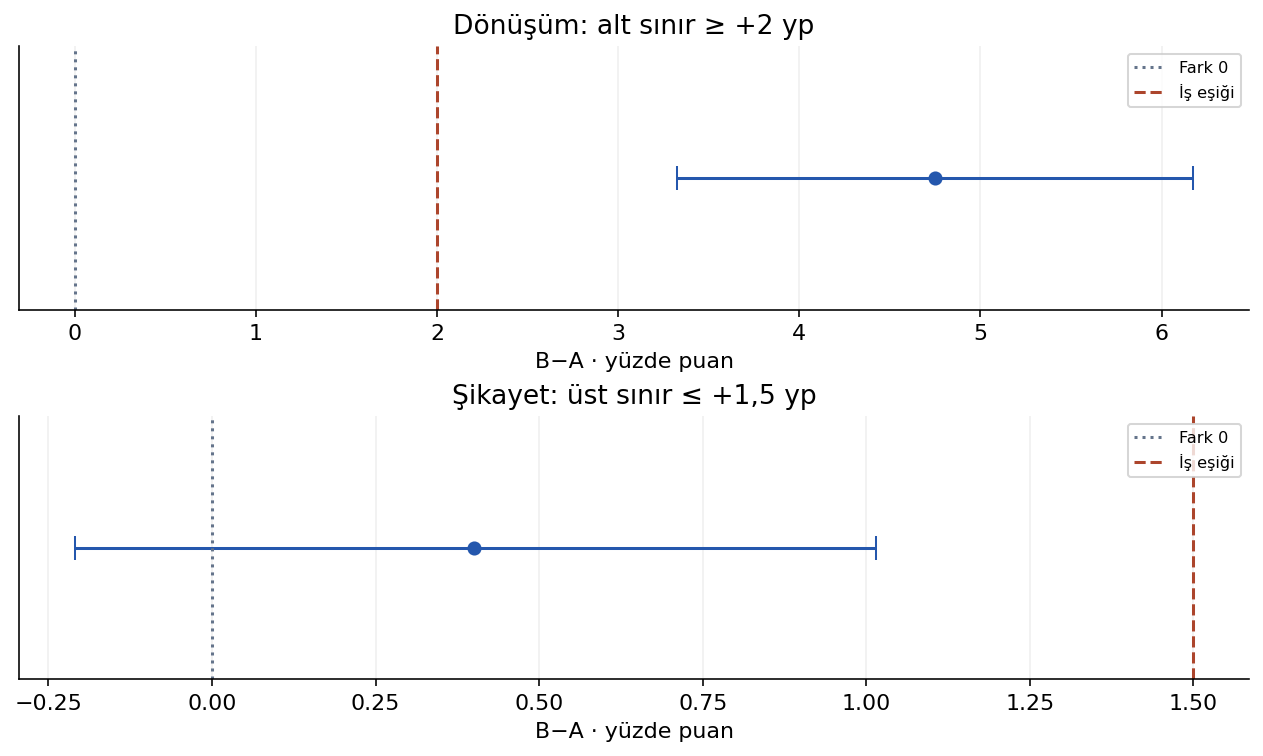

In [2]:
result = experiment('default')
print_result(result)
plt.show()


## Aynı dönüşüm, daha fazla şikayet

A kolunda 70, B kolunda 175 şikayet var. Her kolda 4.000 müşteri. B−A şikayet farkı kaç yüzde puan?


Müşteri / kol: 4000
Yaklaşık güç planı / kol: 1774
Dönüşüm farkı · yp: 4.749999999999998
Şikayet farkı · yp: 2.6249999999999996
İki karar koşulu: Sağlanmadı

Ayrı ölçütler için Newcombe %95 fark aralıkları
   Ölçü  A olay  B olay   A %    B %  Fark · yp  Alt · yp  Üst · yp  İş eşiği · yp
Dönüşüm     387     577 9.675 14.425      4.750  3.327073  6.175322            2.0
Şikayet      70     175 1.750  4.375      2.625  1.878861  3.394562            1.5

Karar: Bir karar koşulu sağlanmadı. Artan dönüşüm tek başına yaygınlaştırma için yeterli kanıt değil. Şikayet nedenlerini ve etki aralığını incele.
Koşullar: Bir müşteri bir atama, bağımsız birimler ve tam takip varsayılır. Sonuçlar önceden belirlenen tek final analizine aittir. Alt gruplarda sonradan aranan farklar doğrulama gerektirir.


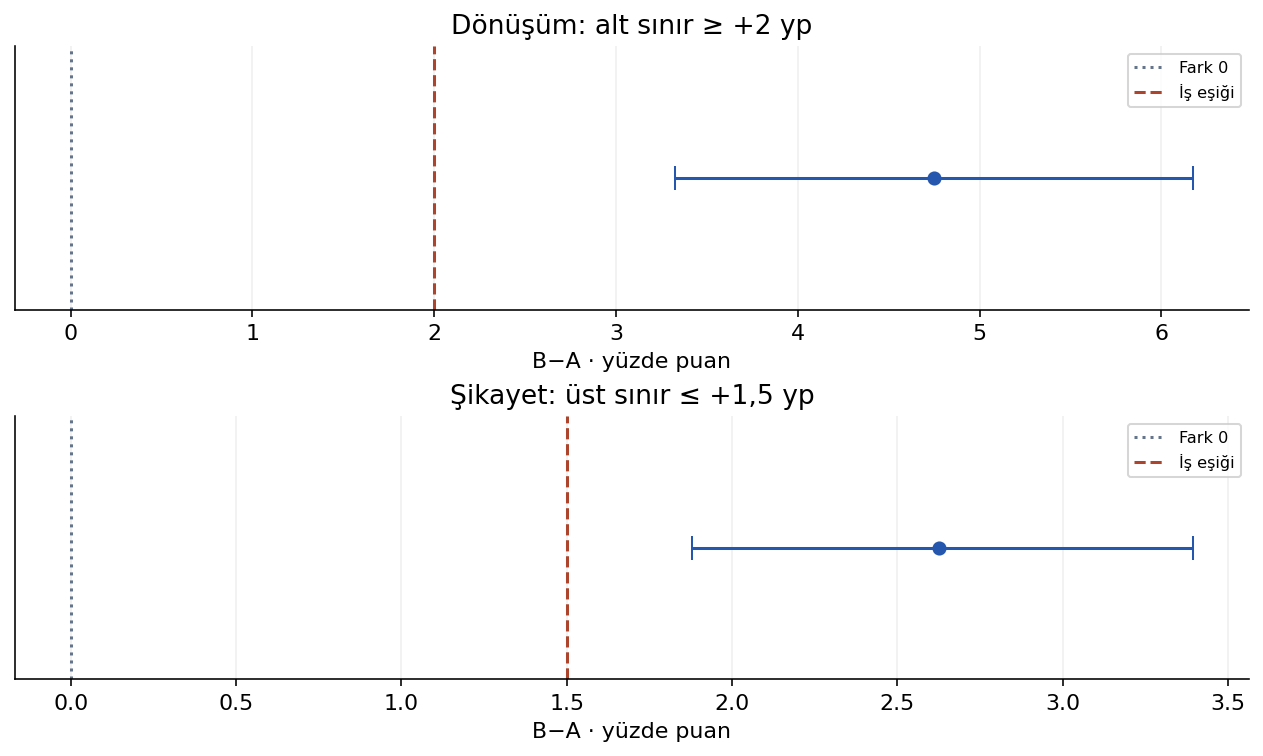

In [3]:
result = experiment('complaints')
print_result(result)
plt.show()


## Karar notu

Birinci senaryodan ikinciye geç. Dönüşüm aynı kaldığı halde kararın neden değiştiğini aralık uçları ve iş eşikleriyle açıkla.

- Kazanımın alt ve şikayetin üst ucunu doğru karşılaştır.
- Sıfıra karşı güç hesabıyla iş eşiğine karşı başarıyı ayır.
- Karar koşulu sağlanmayan senaryoda ek incelemeyi belirt.